# Stroke Dataset EDA and Cleaning

Explore the supplied stroke dataset, inspect data quality, and prepare a modeling-ready table.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

BASE_DIR = Path.cwd().resolve()
if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent
sys.path.insert(0, str(BASE_DIR))

DATA_PATH = BASE_DIR / "data" / "raw" / "full_filled_stroke_data (1).csv"
df = pd.read_csv(DATA_PATH)
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,31.555602,never smoked,1
1,Female,59.0,0,0,Yes,Private,Rural,76.15,30.242937,Unknown,1
2,Male,78.0,0,1,Yes,Private,Urban,219.84,30.698951,Unknown,1
3,Male,57.0,0,1,No,Govt_job,Urban,217.08,33.808410,Unknown,1
4,Male,58.0,0,0,Yes,Private,Rural,189.84,31.378534,Unknown,1


In [2]:
print(f"Shape: {df.shape}")
print("\nData types:")
display(df.dtypes.to_frame("dtype"))
print("\nMissing values:")
display(df.isna().sum().to_frame("missing"))
print("\nDuplicate rows:", df.duplicated().sum())
print("\nTarget distribution:")
display(df["stroke"].value_counts().rename("count").to_frame())

Shape: (201, 11)

Data types:


,dtype
gender,object
age,float64
hypertension,int64
heart_disease,int64
ever_married,object
work_type,object
Residence_type,object
avg_glucose_level,float64
bmi,float64
smoking_status,object



Missing values:


,missing
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,0
smoking_status,0



Duplicate rows: 0

Target distribution:


,count
stroke,
0,161
1,40


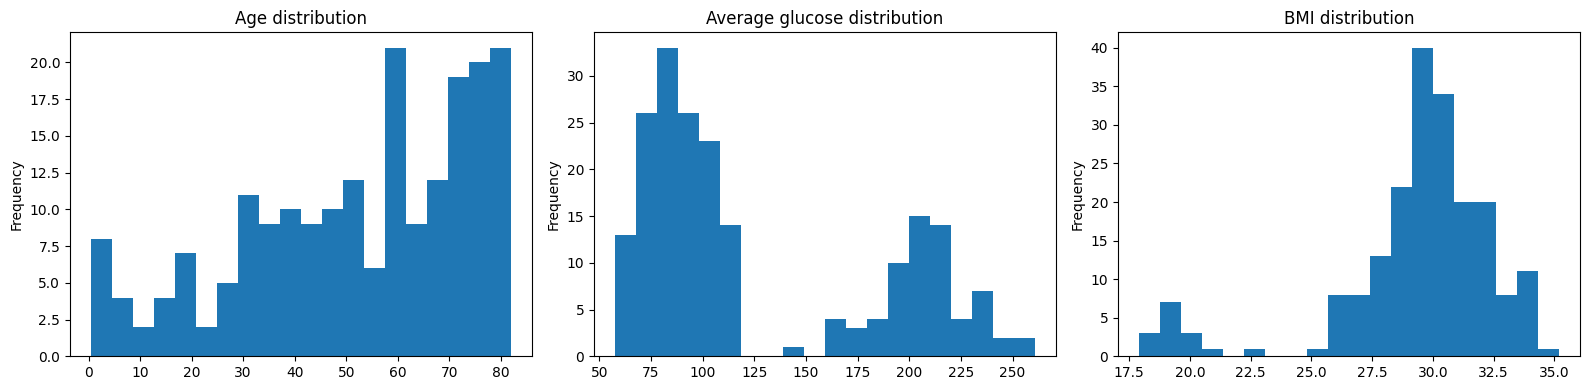

,age,hypertension,heart_disease,avg_glucose_level,bmi
stroke,,,,,
0,48.13,0.25,0.16,127.91,29.33
1,67.81,0.15,0.18,121.96,29.36


In [3]:
numeric_columns = ["age", "hypertension", "heart_disease", "avg_glucose_level", "bmi"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
df["age"].plot(kind="hist", bins=20, ax=axes[0], title="Age distribution")
df["avg_glucose_level"].plot(kind="hist", bins=20, ax=axes[1], title="Average glucose distribution")
df["bmi"].plot(kind="hist", bins=20, ax=axes[2], title="BMI distribution")
plt.tight_layout()
plt.show()

display(df.groupby("stroke")[numeric_columns].mean().round(2))

In [4]:
categorical_columns = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]
for column in categorical_columns:
    print(f"\n{column}")
    display(df[column].value_counts(dropna=False).rename("count").to_frame())

cleaned_df = df.drop_duplicates().reset_index(drop=True)
print(f"Cleaned shape: {cleaned_df.shape}")


gender


,count
gender,
Male,104
Female,97



ever_married


,count
ever_married,
Yes,149
No,52



work_type


...


Residence_type


,count
Residence_type,
Urban,106
Rural,95



smoking_status


,count
smoking_status,
Unknown,61
smokes,52
formerly smoked,48
never smoked,40


Cleaned shape: (201, 11)
